# Non-linear static analysis with the Newton-Raphson method

This example solves a geometrically non-linear problem, a plate whose deflection is several times its thickness, with a full Newton-Raphson method written in a few lines, and compares the result with the closed-form solution of Timoshenko and Woinowsky-Krieger (1959). It then checks that the tangent stiffness matrix is the exact derivative of the internal force vector, which makes the method converge quadratically.

The geometrically non-linear models provide the internal force vector $\boldsymbol{F}_{int}(\boldsymbol{c})$, `Shell.calc_fint`, and the tangent stiffness matrix

$$
\boldsymbol{K}_T = \frac{\partial \boldsymbol{F}_{int}}{\partial \boldsymbol{c}} = \boldsymbol{K}_C + \boldsymbol{K}_G,
$$

`Shell.calc_kT`, or `Shell.calc_kC` plus `Shell.calc_kG` with the current $\boldsymbol{c}$. Equilibrium is the root of the residual $\boldsymbol{R}(\boldsymbol{c}) = \boldsymbol{F}_{int}(\boldsymbol{c}) - \boldsymbol{F}_{ext}$. Each Newton-Raphson iteration solves the linearized system

$$
\boldsymbol{K}_T(\boldsymbol{c}_k)\, \Delta\boldsymbol{c} = -\boldsymbol{R}(\boldsymbol{c}_k), \qquad \boldsymbol{c}_{k+1} = \boldsymbol{c}_k + \Delta\boldsymbol{c}.
$$

Near the solution the error of the next iteration is proportional to the square of the current one, $e_{k+1} \approx C e_k^2$, only when $\boldsymbol{K}_T$ is the exact derivative of $\boldsymbol{F}_{int}$. See also [Tangent stiffness matrix and its product by a vector](../tangent_product.rst).

In [1]:
%matplotlib inline
import numpy as np
from scipy.optimize import brentq
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import solve
from panels import modelDB
from panels.shell import Shell


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## Plate and load

The case is the numerical example of Timoshenko and Woinowsky-Krieger (1959), Art. 2, pp. 11-12: a long rectangular steel plate of width $l = 50$ in and thickness $h = 1/2$ in ($l/h = 100$), $E = 30 \times 10^6$ psi, $\nu = 0.3$, under a uniform pressure $q = 20$ psi. Its longitudinal edges are simply supported and cannot move toward each other, so the deflection stretches the middle surface and an axial tensile force $S$ per unit length develops. The plate bends to a cylindrical surface; with the lateral strain prevented, it is a strip of bending stiffness $D = E h^3/[12(1 - \nu^2)]$. The lengths are in inches and the forces in pounds.

The plate of `panels` has $a = l$ along $x$ and $b = l$ along $y$. At $x = 0, a$: $u = v = w = 0$, the rotation free (with $\phi_y = 0$ in the shear deformation theories). At $y = 0, b$: $v = 0$ and the slope $w_{,y} = 0$ (`y1wr = y2wr = 0`, or $\phi_y = 0$), the conditions of symmetry of a strip cut from an infinitely long plate, while $u$ and $w$ are free. The solution is then independent of $y$, with $v = 0$ everywhere: the plane-strain cylindrical bending of the reference.

In [2]:
L = 50.     # in
H = 0.5     # in
E, NU = 30e6, 0.3  # psi
Q = 20.     # psi
D = E*H**3/(12*(1 - NU**2))


def build_plate(model, m=15, n=4):
    s = Shell(model=model, a=L, b=L, m=m, n=n, stack=[0.], plyt=H,
              laminaprop=(E, NU), r=1.e15 if model.startswith('cylshell') else None)
    for edge in ('x1', 'x2', 'y1', 'y2'):
        for field in ('u', 'v', 'w', 'phix', 'phiy'):
            setattr(s, edge + field, 1.)
            setattr(s, edge + field + 'r', 1.)
    for edge in ('x1', 'x2'):
        for field in ('u', 'v', 'w', 'phiy'):
            setattr(s, edge + field, 0.)
    for edge in ('y1', 'y2'):
        for field in ('v', 'wr', 'phiy'):
            setattr(s, edge + field, 0.)
    s.add_pressure_load(Q)
    return s

## Newton-Raphson iterations

The iterations start from the linear solution $\boldsymbol{K}_C \boldsymbol{c}_0 = \boldsymbol{F}_{ext}$ and apply the full load in a single step. Convergence is measured by Crisfield's criterion: the norm of the residual relative to the larger of the norms of $\boldsymbol{F}_{ext}$ and $\boldsymbol{F}_{int}$. Each norm is scaled by the diagonal $\boldsymbol{D}$ of $\boldsymbol{K}_C$, $\|\boldsymbol{v}\|_D = \sqrt{\boldsymbol{v}^\top |\boldsymbol{D}|^{-1} \boldsymbol{v}}$, without the null entries of $\boldsymbol{D}$ (constrained terms).

In [3]:
def scaled_norm(vec, D):
    keep = ~np.isclose(D, 0)
    return np.sqrt((vec[keep]/np.abs(D[keep])) @ vec[keep])


def newton_raphson(s, tol=1.e-10, maxiter=40):
    fext = s.calc_fext()
    kC = s.calc_kC()
    c = solve(kC, fext, silent=True)
    c_lin = c.copy()
    D = kC.diagonal()
    errors = []
    while True:
        R = s.calc_fint(c=c) - fext
        fint = R + fext
        errors.append(scaled_norm(R, D)/max(scaled_norm(fext, D),
                                            scaled_norm(fint, D)))
        if errors[-1] < tol or len(errors) > maxiter:
            break
        c = c + solve(s.calc_kT(c=c), -R, silent=True)
    return c_lin, c, errors


s = build_plate('plate_clpt_donnell')
c_lin, c, errors = newton_raphson(s)
for k, e in enumerate(errors):
    print('iteration %2d, Crisfield criterion %.3e' % (k, e))
orders = [np.log(e1)/np.log(e0) for e0, e1 in zip(errors[:-1], errors[1:])
          if 1.e-15 < e1 and e0 < 1.e-2]
print('convergence orders log(e_k+1)/log(e_k) in the asymptotic range:',
      np.round(orders, 3))

iteration  0, Crisfield criterion 9.976e-01
iteration  1, Crisfield criterion 9.884e-01
iteration  2, Crisfield criterion 9.718e-01
iteration  3, Crisfield criterion 9.091e-01
iteration  4, Crisfield criterion 7.636e-01
iteration  5, Crisfield criterion 4.576e-01
iteration  6, Crisfield criterion 1.305e-01
iteration  7, Crisfield criterion 8.110e-03
iteration  8, Crisfield criterion 3.019e-05
iteration  9, Crisfield criterion 4.214e-10
iteration 10, Crisfield criterion 4.928e-16
convergence orders log(e_k+1)/log(e_k) in the asymptotic range: [2.162 2.074]


The linear solution, the starting point, has a deflection of about ten thicknesses, about seven times the non-linear one. In the first iterations the membrane tension builds up and the error decreases slowly. Once it is small, the number of correct digits roughly doubles at each iteration.

## The closed-form solution

With $u^2 = S l^2/(4D)$ (Eq. (5)), the deflection of the strip is (Eq. (6))

$$
w = \frac{q l^4}{16 u^4 D}\left[\frac{\cosh u\left(1 - \dfrac{2x}{l}\right)}{\cosh u} - 1\right] + \frac{q l^2 x}{8 u^2 D}(l - x),
$$

and the condition that the edges do not move gives $u$ from Eq. (8),

$$
\frac{E^2 h^8}{(1 - \nu^2)^2 q^2 l^8} = \frac{135}{16}\frac{\tanh u}{u^9} + \frac{27}{16}\frac{\tanh^2 u}{u^8} - \frac{135}{16 u^8} + \frac{9}{8 u^6}.
$$

The maximum deflection is (Eq. (12))

$$
w_{max} = \frac{5 q l^4}{384 D} f_0(u), \qquad f_0(u) = \frac{\operatorname{sech} u - 1 + u^2/2}{5u^4/24},
$$

where $5ql^4/(384D)$ is the linear deflection, the membrane stress is $\sigma_1 = S/h$ (Eq. (10)) and the largest bending stress is $\sigma_2 = 6M_{max}/h^2 = \frac{3}{4} q (l/h)^2 \psi_0(u)$ (Eq. (11)), with $\psi_0 = (1 - \operatorname{sech} u)/(u^2/2)$ (Eq. (e), p. 9). Timoshenko and Woinowsky-Krieger read $u = 3.795$, $\psi_0 = 0.1329$ and $f_0 = 0.145$ from their curves (Figs. 4 and 5) and obtain $w_{max} = 0.688$ in, $\sigma_1 = 15{,}830$ psi and $\sigma_2 = 19{,}930$ psi; the linear deflection is $4.74$ in. Below, Eq. (8) is solved numerically instead:

In [4]:
lhs = E**2*H**8/((1 - NU**2)**2*Q**2*L**8)
rhs = lambda u: (135/16*np.tanh(u)/u**9 + 27/16*np.tanh(u)**2/u**8
                 - 135/(16*u**8) + 9/(8*u**6))
u_ref = brentq(lambda u: rhs(u) - lhs, 0.5, 20.)
S_ref = 4*u_ref**2*D/L**2
f0 = (1/np.cosh(u_ref) - 1 + u_ref**2/2)/(5*u_ref**4/24)
psi0 = (1 - 1/np.cosh(u_ref))/(u_ref**2/2)
w_lin_ref = 5*Q*L**4/(384*D)
w_ref = w_lin_ref*f0
sigma1_ref = S_ref/H
sigma2_ref = 3/4*Q*(L/H)**2*psi0


def w_closed_form(x):
    u = u_ref
    return (Q*L**4/(16*u**4*D)*(np.cosh(u*(1 - 2*x/L))/np.cosh(u) - 1)
            + Q*L**2*x/(8*u**2*D)*(L - x))


print('u = %.4f, f0 = %.4f, psi0 = %.4f' % (u_ref, f0, psi0))
print('w_max = %.4f in (linear %.4f in), sigma_1 = %.0f psi, sigma_2 = %.0f psi'
      % (w_ref, w_lin_ref, sigma1_ref, sigma2_ref))

u = 3.7938, f0 = 0.1446, psi0 = 0.1327
w_max = 0.6854 in (linear 4.7396 in), sigma_1 = 15817 psi, sigma_2 = 19905 psi


The convergence of the iterations, and the deflection along $y = b/2$ against Eq. (6):

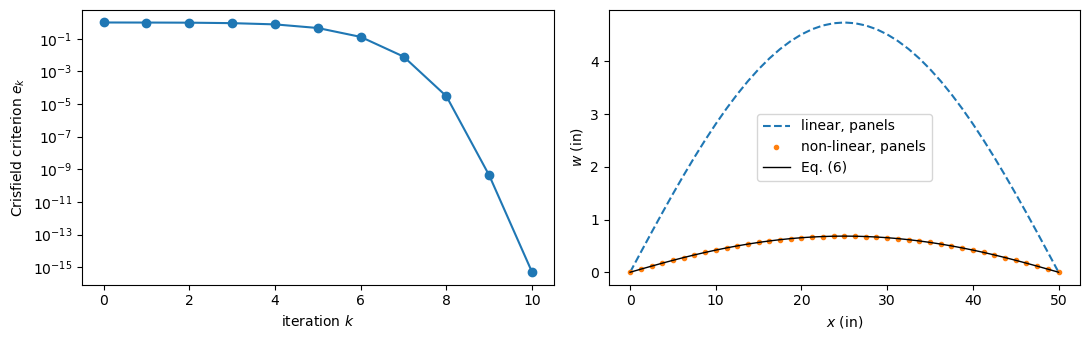

largest difference to Eq. (6) along y = b/2: 3.5e-09 in


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].semilogy(errors, 'o-')
axes[0].set_xlabel('iteration $k$')
axes[0].set_ylabel('Crisfield criterion $e_k$')
xs = np.linspace(0, L, 41)
ys = np.full_like(xs, L/2)
w_lin = s.uvw(c_lin, xs=xs, ys=ys)[1]['w'].copy()
w_nl = s.uvw(c, xs=xs, ys=ys)[1]['w'].copy()
axes[1].plot(xs, w_lin, '--', label='linear, panels')
axes[1].plot(xs, w_nl, 'o', ms=3, label='non-linear, panels')
axes[1].plot(xs, w_closed_form(xs), 'k-', lw=1, label='Eq. (6)')
axes[1].set_xlabel('$x$ (in)')
axes[1].set_ylabel('$w$ (in)')
axes[1].legend()
fig.tight_layout()
plt.show()
print('largest difference to Eq. (6) along y = b/2: %.1e in'
      % np.abs(w_nl - w_closed_form(xs)).max())

## Five models

The same analysis with the plate and cylindrical-shell (radius $10^{15}$ in) models of the CLPT, and with the FSDT and TSDT plates. The deflections and the stresses at the center are compared with the closed-form values computed above, and with the values printed by Timoshenko and Woinowsky-Krieger, which come from curves and are accurate to about three digits. The membrane stress is $N_{xx}/h$ and the bending stress $6|M_{xx}|/h^2$, from `Shell.stress`.

In [6]:
SRC = 'Timoshenko and Woinowsky-Krieger (1959)'
rows = []
for model in ['plate_clpt_donnell', 'cylshell_clpt_donnell',
              'cylshell_clpt_sanders', 'plate_fsdt_donnell',
              'plate_tsdt_donnell']:
    s = build_plate(model)
    c_lin, c, errors = newton_raphson(s)
    xc, yc = np.array([L/2]), np.array([L/2])
    wlin = s.uvw(c=c_lin, xs=xc, ys=yc)[1]['w'][0]
    wnl = s.uvw(c=c, xs=xc, ys=yc)[1]['w'][0]
    f = s.stress(c=c, xs=xc, ys=yc)[1]
    sigma1 = f['Nxx'][0]/H
    sigma2 = 6*abs(f['Mxx'][0])/H**2
    print('%-22s linear w %.4f in, non-linear w %.5f in, sigma_1 %.0f psi, '
          'sigma_2 %.0f psi, %d iterations'
          % (model, wlin, wnl, sigma1, sigma2, len(errors) - 1))
    m = '`%s`' % model
    rows += [
        (m + ', linear $w_{max}$ (in)', wlin, w_lin_ref, SRC + r', $5ql^4/(384D)$'),
        (m + ', $w_{max}$ (in)', wnl, w_ref, SRC + ', Eqs. (8) and (12)'),
        (m + ', $w_{max}$ (in)', wnl, 0.688, SRC + ', p. 12, from curves'),
        (m + r', $\sigma_1$ (psi)', sigma1, sigma1_ref, SRC + ', Eqs. (8) and (10)'),
        (m + r', $\sigma_1$ (psi)', sigma1, 15830., SRC + ', p. 11, from curves'),
        (m + r', $\sigma_2$ (psi)', sigma2, sigma2_ref, SRC + ', Eqs. (8) and (11)'),
        (m + r', $\sigma_2$ (psi)', sigma2, 19930., SRC + ', p. 11, from curves'),
    ]
results_table(rows)

plate_clpt_donnell     linear w 4.7396 in, non-linear w 0.68543 in, sigma_1 15817 psi, sigma_2 19905 psi, 10 iterations


cylshell_clpt_donnell  linear w 4.7396 in, non-linear w 0.68543 in, sigma_1 15817 psi, sigma_2 19905 psi, 10 iterations


cylshell_clpt_sanders  linear w 4.7396 in, non-linear w 0.68543 in, sigma_1 15817 psi, sigma_2 19905 psi, 10 iterations


plate_fsdt_donnell     linear w 4.7409 in, non-linear w 0.68543 in, sigma_1 15817 psi, sigma_2 19902 psi, 10 iterations


plate_tsdt_donnell     linear w 4.7409 in, non-linear w 0.68543 in, sigma_1 15817 psi, sigma_2 19902 psi, 10 iterations


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, linear $w_{max}$ (in) | 4.73958 | 4.73958 | -2.25e-15 | Timoshenko and Woinowsky-Krieger (1959), $5ql^4/(384D)$ |
| `plate_clpt_donnell`, $w_{max}$ (in) | 0.685431 | 0.685431 | -5.05e-09 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (12) |
| `plate_clpt_donnell`, $w_{max}$ (in) | 0.685431 | 0.688 | -3.73e-03 | Timoshenko and Woinowsky-Krieger (1959), p. 12, from curves |
| `plate_clpt_donnell`, $\sigma_1$ (psi) | 15816.6 | 15816.6 | -1.30e-06 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (10) |
| `plate_clpt_donnell`, $\sigma_1$ (psi) | 15816.6 | 15830 | -8.46e-04 | Timoshenko and Woinowsky-Krieger (1959), p. 11, from curves |
| `plate_clpt_donnell`, $\sigma_2$ (psi) | 19905.4 | 19905.4 | -3.53e-07 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (11) |
| `plate_clpt_donnell`, $\sigma_2$ (psi) | 19905.4 | 19930 | -1.23e-03 | Timoshenko and Woinowsky-Krieger (1959), p. 11, from curves |
| `cylshell_clpt_donnell`, linear $w_{max}$ (in) | 4.73958 | 4.73958 | -2.25e-15 | Timoshenko and Woinowsky-Krieger (1959), $5ql^4/(384D)$ |
| `cylshell_clpt_donnell`, $w_{max}$ (in) | 0.685431 | 0.685431 | -5.05e-09 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (12) |
| `cylshell_clpt_donnell`, $w_{max}$ (in) | 0.685431 | 0.688 | -3.73e-03 | Timoshenko and Woinowsky-Krieger (1959), p. 12, from curves |
| `cylshell_clpt_donnell`, $\sigma_1$ (psi) | 15816.6 | 15816.6 | -1.30e-06 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (10) |
| `cylshell_clpt_donnell`, $\sigma_1$ (psi) | 15816.6 | 15830 | -8.46e-04 | Timoshenko and Woinowsky-Krieger (1959), p. 11, from curves |
| `cylshell_clpt_donnell`, $\sigma_2$ (psi) | 19905.4 | 19905.4 | -3.53e-07 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (11) |
| `cylshell_clpt_donnell`, $\sigma_2$ (psi) | 19905.4 | 19930 | -1.23e-03 | Timoshenko and Woinowsky-Krieger (1959), p. 11, from curves |
| `cylshell_clpt_sanders`, linear $w_{max}$ (in) | 4.73958 | 4.73958 | -2.44e-15 | Timoshenko and Woinowsky-Krieger (1959), $5ql^4/(384D)$ |
| `cylshell_clpt_sanders`, $w_{max}$ (in) | 0.685431 | 0.685431 | -5.05e-09 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (12) |
| `cylshell_clpt_sanders`, $w_{max}$ (in) | 0.685431 | 0.688 | -3.73e-03 | Timoshenko and Woinowsky-Krieger (1959), p. 12, from curves |
| `cylshell_clpt_sanders`, $\sigma_1$ (psi) | 15816.6 | 15816.6 | -1.30e-06 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (10) |
| `cylshell_clpt_sanders`, $\sigma_1$ (psi) | 15816.6 | 15830 | -8.46e-04 | Timoshenko and Woinowsky-Krieger (1959), p. 11, from curves |
| `cylshell_clpt_sanders`, $\sigma_2$ (psi) | 19905.4 | 19905.4 | -3.53e-07 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (11) |
| `cylshell_clpt_sanders`, $\sigma_2$ (psi) | 19905.4 | 19930 | -1.23e-03 | Timoshenko and Woinowsky-Krieger (1959), p. 11, from curves |
| `plate_fsdt_donnell`, linear $w_{max}$ (in) | 4.74088 | 4.73958 | +2.74e-04 | Timoshenko and Woinowsky-Krieger (1959), $5ql^4/(384D)$ |
| `plate_fsdt_donnell`, $w_{max}$ (in) | 0.685427 | 0.685431 | -6.63e-06 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (12) |
| `plate_fsdt_donnell`, $w_{max}$ (in) | 0.685427 | 0.688 | -3.74e-03 | Timoshenko and Woinowsky-Krieger (1959), p. 12, from curves |
| `plate_fsdt_donnell`, $\sigma_1$ (psi) | 15817.1 | 15816.6 | +3.25e-05 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (10) |
| `plate_fsdt_donnell`, $\sigma_1$ (psi) | 15817.1 | 15830 | -8.12e-04 | Timoshenko and Woinowsky-Krieger (1959), p. 11, from curves |
| `plate_fsdt_donnell`, $\sigma_2$ (psi) | 19901.9 | 19905.4 | -1.78e-04 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (11) |
| `plate_fsdt_donnell`, $\sigma_2$ (psi) | 19901.9 | 19930 | -1.41e-03 | Timoshenko and Woinowsky-Krieger (1959), p. 11, from curves |
| `plate_tsdt_donnell`, linear $w_{max}$ (in) | 4.74088 | 4.73958 | +2.74e-04 | Timoshenko and Woinowsky-Krieger (1959), $5ql^4/(384D)$ |
| `plate_tsdt_donnell`, $w_{max}$ (in) | 0.685427 | 0.685431 | -6.63e-06 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (12) |
| `plate_tsdt_donnell`, $w_{max}$ (in) | 0.685427 | 0.688 | -3.74e-03 | Timoshenko and Woinowsky-Krieger (1959), p. 12, from curves |
| `plate_tsdt_donnell`, $\sigma_1$ (psi) | 15817.1 | 15816.6 | +3.26e-05 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (10) |
| `plate_tsdt_donnell`, $\sigma_1$ (psi) | 15817.1 | 15830 | -8.12e-04 | Timoshenko and Woinowsky-Krieger (1959), p. 11, from curves |
| `plate_tsdt_donnell`, $\sigma_2$ (psi) | 19901.9 | 19905.4 | -1.78e-04 | Timoshenko and Woinowsky-Krieger (1959), Eqs. (8) and (11) |
| `plate_tsdt_donnell`, $\sigma_2$ (psi) | 19901.9 | 19930 | -1.41e-03 | Timoshenko and Woinowsky-Krieger (1959), p. 11, from curves |

The CLPT models solve the von Kármán equations of the reference and reproduce the closed form: the plate is flat and the Donnell and Sanders kinematics of the cylindrical shells reduce to those of the plate for $r = 10^{15}$ in. The FSDT and TSDT add the transverse shear deformation, small for $l/h = 100$. The values printed in the book differ from the closed form by up to 0.4% because $u$, $f_0$ and $\psi_0$ were read from curves.

## Consistency of the tangent stiffness matrix

The Taylor expansion of $\boldsymbol{F}_{int}$ about a state $\boldsymbol{c}$ along a direction $\boldsymbol{d}$,

$$
\boldsymbol{F}_{int}(\boldsymbol{c} + h\boldsymbol{d}) = \boldsymbol{F}_{int}(\boldsymbol{c}) + h \boldsymbol{K}_T(\boldsymbol{c})\boldsymbol{d} + O(h^2),
$$

gives the relative error $e(h) = \|\boldsymbol{F}_{int}(\boldsymbol{c} + h\boldsymbol{d}) - \boldsymbol{F}_{int}(\boldsymbol{c}) - h\boldsymbol{K}_T\boldsymbol{d}\| / (h \|\boldsymbol{K}_T\boldsymbol{d}\|)$. It decreases linearly with $h$, a factor of ten per decade, when $\boldsymbol{K}_T$ is the exact derivative. An inconsistent tangent leaves a first-order remainder, and $e(h)$ stops decreasing.

The state and the direction are random, with large deflections. The panel of $0.3 \times 0.2$ m has the unsymmetric and unbalanced laminate $[30/-45/0/90]$, so $A_{16}$, $A_{26}$ and $\boldsymbol{B}$ are not zero, and all the terms of the kinematics are exercised. Cylindrical shells have $r = 0.4$ m. The test covers the eleven non-linear models, including the Green-Lagrange (`plate_clpt_gl`) and total Lagrangian (`plate_clpt_tl`) plates.

In [7]:
MODELS = ['plate_clpt_donnell', 'cylshell_clpt_donnell',
          'cylshell_clpt_sanders', 'plate_fsdt_donnell', 'plate_tsdt_donnell',
          'cylshell_fsdt_donnell', 'cylshell_fsdt_sanders',
          'cylshell_tsdt_donnell', 'cylshell_tsdt_sanders', 'plate_clpt_gl',
          'plate_clpt_tl']


def make_shell(model):
    E11 = 142.5e9
    E22 = E11/20
    G12 = 0.5*E22
    s = Shell(model=model, a=0.3, b=0.2, m=5, n=5, plyt=0.125e-3,
              stack=[30, -45, 0, 90], laminaprop=(E11, E22, 0.25, G12, G12, G12),
              r=0.4 if model.startswith('cylshell') else None)
    s.nx = s.ny = 8
    for edge in ('x1', 'x2', 'y1', 'y2'):
        for field in 'uvw':
            setattr(s, edge + field, 0. if field == 'w' else 1.)
            setattr(s, edge + field + 'r', 1.)
    s.x1u = 0.
    s.y1v = 0.
    return s


def random_state(s, rng):
    h_shell = len(s.stack)*s.plyt
    c = h_shell*rng.standard_normal(s.get_size())
    dofs = modelDB.db[s.model]['dofs']
    c[2::dofs] *= 20  # w, deflections of the order of 20 thicknesses
    if dofs == 5:
        # rotations of the shear deformation theories, of the order of the
        # slopes of w
        c[3::dofs] *= 20/min(s.a, s.b)
        c[4::dofs] *= 20/min(s.a, s.b)
    return c


steps = np.array([1.e-2, 1.e-3, 1.e-4, 1.e-5, 1.e-6])
taylor = {}
rng = np.random.default_rng(0)
for model in MODELS:
    s = make_shell(model)
    c = random_state(s, rng)
    d = random_state(s, rng)
    f0 = s.calc_fint(c=c)
    KTd = s.calc_kT(c=c) @ d
    taylor[model] = np.array([np.linalg.norm(s.calc_fint(c=c + h*d) - f0
                                             - h*KTd)/(h*np.linalg.norm(KTd))
                              for h in steps])
    slope = np.polyfit(np.log10(steps), np.log10(taylor[model]), 1)[0]
    print('%-22s e(h) = %s, slope %.3f' % (model, np.array2string(
          taylor[model], precision=2), slope))

plate_clpt_donnell     e(h) = [1.63e-04 1.63e-05 1.63e-06 1.63e-07 1.65e-08], slope 0.999
cylshell_clpt_donnell  e(h) = [2.82e-05 2.82e-06 2.82e-07 2.82e-08 2.79e-09], slope 1.001
cylshell_clpt_sanders  e(h) = [8.81e-06 8.81e-07 8.81e-08 8.82e-09 9.06e-10], slope 0.998
plate_fsdt_donnell     e(h) = [1.42e-04 1.42e-05 1.42e-06 1.42e-07 1.41e-08], slope 1.001
plate_tsdt_donnell     e(h) = [1.48e-05 1.48e-06 1.48e-07 1.48e-08 1.37e-09], slope 1.006
cylshell_fsdt_donnell  e(h) = [3.38e-05 3.38e-06 3.38e-07 3.37e-08 3.60e-09], slope 0.994
cylshell_fsdt_sanders  e(h) = [3.11e-05 3.11e-06 3.11e-07 3.11e-08 3.06e-09], slope 1.001


cylshell_tsdt_donnell  e(h) = [1.09e-05 1.09e-06 1.09e-07 1.09e-08 1.16e-09], slope 0.994


cylshell_tsdt_sanders  e(h) = [3.71e-05 3.71e-06 3.71e-07 3.71e-08 4.10e-09], slope 0.991
plate_clpt_gl          e(h) = [2.57e-04 2.57e-05 2.57e-06 2.57e-07 2.53e-08], slope 1.001
plate_clpt_tl          e(h) = [9.77e-05 9.77e-06 9.77e-07 9.77e-08 9.60e-09], slope 1.002


The slope of $\log e$ against $\log h$ is 1 for all models, the value of an exact tangent:

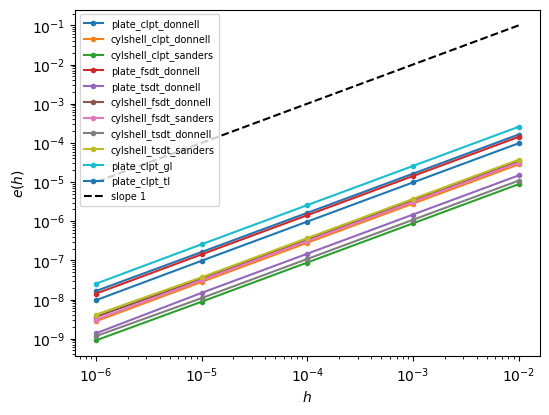

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, slope of $e(h)$ | 0.999185 | 1 | -8.15e-04 | second-order remainder of the Taylor expansion |
| `cylshell_clpt_donnell`, slope of $e(h)$ | 1.00087 | 1 | +8.65e-04 | second-order remainder of the Taylor expansion |
| `cylshell_clpt_sanders`, slope of $e(h)$ | 0.997582 | 1 | -2.42e-03 | second-order remainder of the Taylor expansion |
| `plate_fsdt_donnell`, slope of $e(h)$ | 1.00058 | 1 | +5.83e-04 | second-order remainder of the Taylor expansion |
| `plate_tsdt_donnell`, slope of $e(h)$ | 1.00632 | 1 | +6.32e-03 | second-order remainder of the Taylor expansion |
| `cylshell_fsdt_donnell`, slope of $e(h)$ | 0.994342 | 1 | -5.66e-03 | second-order remainder of the Taylor expansion |
| `cylshell_fsdt_sanders`, slope of $e(h)$ | 1.00144 | 1 | +1.44e-03 | second-order remainder of the Taylor expansion |
| `cylshell_tsdt_donnell`, slope of $e(h)$ | 0.99419 | 1 | -5.81e-03 | second-order remainder of the Taylor expansion |
| `cylshell_tsdt_sanders`, slope of $e(h)$ | 0.991273 | 1 | -8.73e-03 | second-order remainder of the Taylor expansion |
| `plate_clpt_gl`, slope of $e(h)$ | 1.00143 | 1 | +1.43e-03 | second-order remainder of the Taylor expansion |
| `plate_clpt_tl`, slope of $e(h)$ | 1.00153 | 1 | +1.53e-03 | second-order remainder of the Taylor expansion |

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for model, e in taylor.items():
    ax.loglog(steps, e, 'o-', ms=3, label=model)
ax.loglog(steps, steps/steps[0]*1e-1, 'k--', label='slope 1')
ax.set_xlabel('$h$')
ax.set_ylabel('$e(h)$')
ax.legend(fontsize=7)
plt.show()
rows = [('`%s`, slope of $e(h)$' % model,
         np.polyfit(np.log10(steps), np.log10(e), 1)[0], 1.,
         'second-order remainder of the Taylor expansion')
        for model, e in taylor.items()]
results_table(rows)

The product $\boldsymbol{K}_T \boldsymbol{v}$ is also available without assembling $\boldsymbol{K}_T$, at the cost of one evaluation of the internal force vector, with `Shell.calc_kTv` and `MultiDomain.calc_kTv`.

The methods `calc_fext`, `calc_fint`, `calc_kC` and `calc_kG` of `Shell` and `MultiDomain` have the signatures required by `structsolve.Analysis`. It implements the Newton-Raphson method with load control and the arc-length methods, see [Non-linear static analysis with the arc-length methods](ex_arc_length.ipynb).

## References

1. S. Timoshenko and S. Woinowsky-Krieger, "Theory of Plates and Shells". 2nd ed., McGraw-Hill, New York, 1959.